# Active Learning for Label Spreading

Active-learning-style querying on top of Probabilistic Label Spreading (PLS):
does *choosing* which detections to annotate next beat annotating a random
subset at the same budget? Five single-instance query strategies, each cheap
to compute from PLS's own output after every reveal:

1. **Random**: uniform draw from the unlabeled pool -- the baseline.
2. **Aleatoric** (`entropy`): highest Shannon entropy of the current soft
   label estimate `p_hat` -- classic uncertainty sampling ("the model doesn't
   know what class this is").
3. **Epistemic** (`trials`): least total propagated evidence mass -- targets
   nodes the diffusion hasn't meaningfully reached yet, regardless of what
   their current (possibly confident-but-uninformed) estimate says.
4. **Mixture**: an equal, pool-min-max-normalized blend of the two above.
5. **Graph-aware Uncertainty** (`wilson_kernel_norm`): the heat-kernel-weighted
   mean Wilson interval width around each candidate, i.e. how uncertain the
   neighborhood is that its label would inform (one extra linear solve per query).

Querying is one instance at a time (PLS is re-solved after every single
reveal, not in coarse batches), driven by `active_querying.py`;
this notebook only loads and visualizes its results. See that script's own
docstring for the full methodology (deterministic seeding, checkpoint/replay
mechanism, etc.).

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append("../utils")
from plot_layout import set_plot_layout
set_plot_layout(path_to_latex="/home/klees/texlive/2024/bin/x86_64-linux")

pd.set_option("display.max_columns", None)


## 1 Query spread in embedding space

Hypothesis: `entropy`-based querying may repeatedly pick points
from the same locally-ambiguous region (wherever aleatoric uncertainty is
high, many nearby detections can look equally confusing at once), producing
spatially clustered queries, while `trials`-based querying explicitly targets
under-served regions and should spread further; `random` and `mixture` sit
somewhere in between, and `wilson_kernel_norm` (Graph-aware Uncertainty) targets
neighborhoods with weak propagated evidence, similar in spirit to `trials`. The per-step query order is recorded by `active_querying.py` itself
(`active_learning_prototype_query_history_k20_alpha0.9.pkl`, same k=20, alpha=0.9);
for runs made before it recorded this, `reconstruct_query_history.py` replays the
strategy solve-only (no evaluation, same deterministic seeding) to recover it.

In [2]:
import pickle
from scipy.spatial.distance import cdist

with open("experiments/active_learning_prototype_query_history_k20_alpha0.9.pkl", "rb") as f:
    qh = pickle.load(f)

QH_N_DATA = qh["n_data"]
STRATEGY_COLORS_SINGLE = {"random": "slategrey", "entropy": "teal", "trials": "coral", "mixture": "palevioletred",
                          "wilson_kernel_norm": "forestgreen"}
STRATEGY_LABELS = {"random": "Random Querying", "entropy": "Aleatoric Uncertainty", "trials": "Epistemic Uncertainty",
                   "mixture": "Aleatoric \& Epistemic", "wilson_kernel_norm": "Graph-aware Uncertainty"}
# only strategies with a label are shown (the unnormalized "wilson_kernel" is not reported)
QH_STRATEGIES = [s for s in qh["history"] if s in STRATEGY_LABELS]

df_full = pd.read_parquet("../data/matched_dataset/coco_val_matched.parquet")
dataset_qh = df_full[df_full["gdino_score"] >= 0.2].copy().reset_index(drop=True)
assert len(dataset_qh) == QH_N_DATA, "matched_dataset has changed since the query-history reconstruction was run"
embeddings_qh = np.vstack(dataset_qh["gdino_embedding"].to_numpy()).astype(np.float32)

# Flatten each strategy's history into a single ordered array of queried indices
# (seed batch first, tagged as step -1 -- shared/identical across all strategies,
# so not informative for a per-strategy spread comparison; kept only as the
# starting point new queries are measured against).
queried_by_strategy = {}
for strategy in QH_STRATEGIES:
    seed_idx = np.array(qh["history"][strategy][0][1])
    query_idx = np.array([entry[1] for entry in qh["history"][strategy][1:]])
    queried_by_strategy[strategy] = dict(seed=seed_idx, query=query_idx)

print(f"n_data={QH_N_DATA:,}  strategies={QH_STRATEGIES}")
for strategy in QH_STRATEGIES:
    n_q = len(queried_by_strategy[strategy]["query"])
    print(f"  {strategy}: {n_q:,} single-instance queries reconstructed")

n_data=85,991  strategies=['random', 'entropy', 'trials', 'mixture', 'wilson_kernel_norm']
  random: 8,499 single-instance queries reconstructed
  entropy: 8,499 single-instance queries reconstructed
  trials: 8,499 single-instance queries reconstructed
  mixture: 8,499 single-instance queries reconstructed
  wilson_kernel_norm: 8,499 single-instance queries reconstructed


### 1.1 Numeric spread metrics

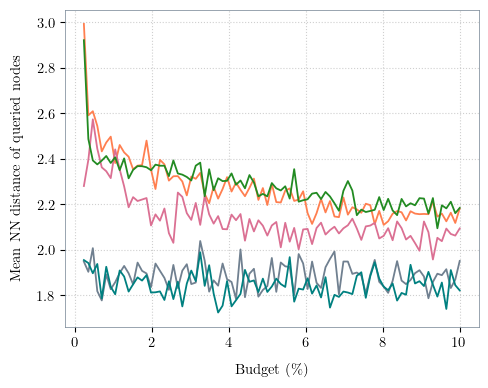

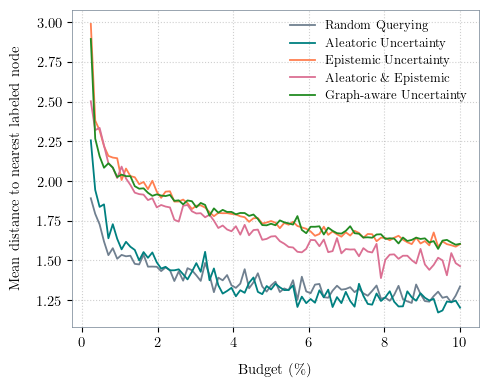

In [3]:
# Single-instance queries have no natural "batch" of their own (batch size 1), so
# these metrics are computed over WINDOWS of WINDOW_SIZE consecutive queries -- the
# same granularity as the single-query study's own eval checkpoints (100).
WINDOW_SIZE = 100

def within_batch_spread(idx):
    if len(idx) < 2:
        return np.nan
    pts = embeddings_qh[idx]
    d = cdist(pts, pts)
    np.fill_diagonal(d, np.inf)
    return float(d.min(axis=1).mean())

def redundancy_vs_existing(idx, labeled_before):
    if len(idx) == 0 or len(labeled_before) == 0:
        return np.nan
    d = cdist(embeddings_qh[idx], embeddings_qh[labeled_before])
    return float(d.min(axis=1).mean())

spread_rows = []
for strategy in QH_STRATEGIES:
    seed_idx = queried_by_strategy[strategy]["seed"]
    query_idx = queried_by_strategy[strategy]["query"]
    for w_start in range(0, len(query_idx), WINDOW_SIZE):
        window = query_idx[w_start:w_start + WINDOW_SIZE]
        labeled_before = np.concatenate([seed_idx, query_idx[:w_start]])
        n_labeled = len(labeled_before) + len(window)
        spread_rows.append(dict(
            strategy=strategy, n_labeled=n_labeled, n_new=len(window),
            within_batch_spread=within_batch_spread(window),
            redundancy_vs_existing=redundancy_vs_existing(window, labeled_before),
        ))
spread_df = pd.DataFrame(spread_rows)

spread_df["budget_pct"] = spread_df["n_labeled"] / QH_N_DATA * 100

spread_df.to_csv("experiments/active_learning_prototype_spread_single_query.csv", index=False)

# Saved as two separate figures (rather than one side-by-side panel) so each can
# be dropped into a LaTeX \subfigure independently.
METRIC_INFO = [
    ("within_batch_spread", "spread", "Mean NN distance of queried nodes"),
    ("redundancy_vs_existing", "redundancy", "Mean distance to nearest labeled node"),
]
for metric, fname_suffix, ylabel in METRIC_INFO:
    fig, ax = plt.subplots(figsize=(5, 4))
    for strategy in QH_STRATEGIES:
        sub = spread_df[spread_df["strategy"] == strategy].sort_values("n_labeled")
        ax.plot(sub["budget_pct"], sub[metric], color=STRATEGY_COLORS_SINGLE[strategy],
                 label=STRATEGY_LABELS[strategy], linewidth=1.3)
    ax.set_xlabel(r"Budget (\%)")
    ax.set_ylabel(ylabel)
    ax.grid(True, ls=":", alpha=0.6)
    if metric == "redundancy_vs_existing": 
        ax.legend(fontsize=9, frameon=False)
    plt.tight_layout()
    plt.savefig(f"plots/active_learning_prototype_spread_single_query_{fname_suffix}.pdf", dpi=300)
    plt.show()


### 1.2 2D visualization (UMAP projection)

/home/klees/miniconda3/envs/label_spreading/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loaded cached UMAP projection -> experiments/active_learning_prototype_umap_embedding.npy  (shape=(85991, 2))


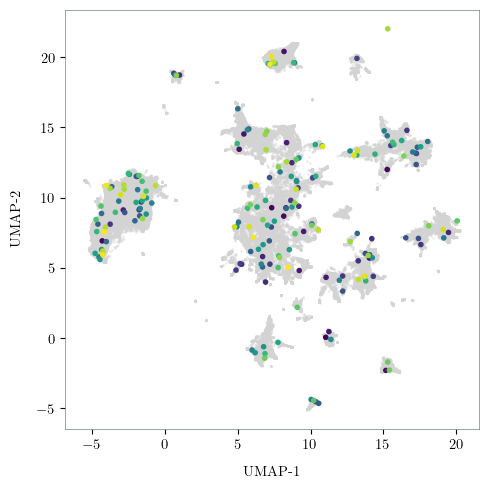

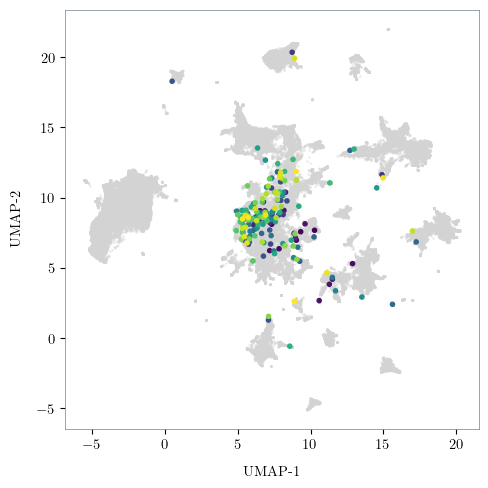

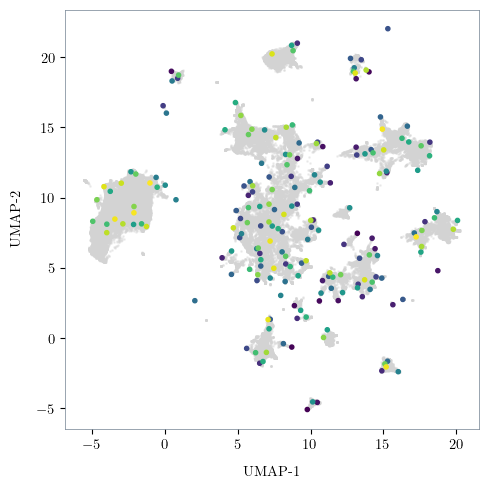

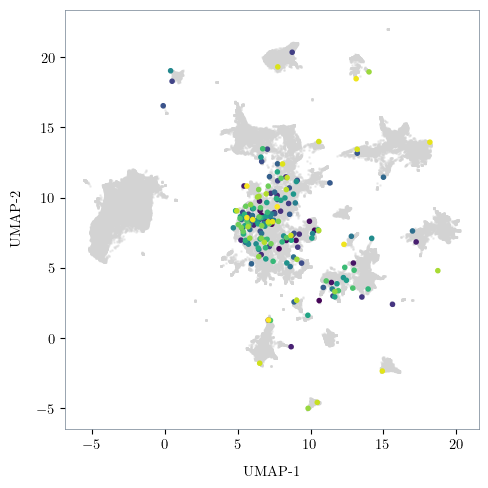

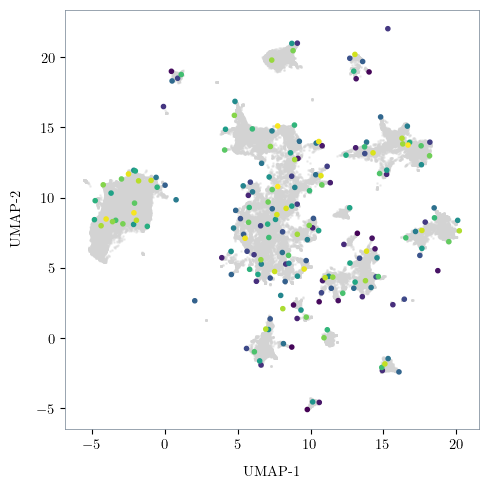

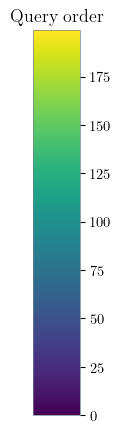

In [4]:
import umap
import time

# DISPLAY_BUDGET_N controls how many queries (in order) get plotted -- start at 1%
# for readability (dense query clouds at 10% get visually cluttered), bump to
# QH's full budget (8,599) if that turns out to still be legible/interesting.
DISPLAY_BUDGET_N = 200   # first 200 queries (~0.2% of QH_N_DATA); 8499 shows all queries up to the 10% budget

# UMAP fit_transform takes ~1min on this dataset (86k embeddings) -- cached to
# disk so re-running this cell while iterating on the plots below doesn't pay
# that cost again. Delete the cache file to force a recompute (e.g. if the
# underlying matched_dataset/embeddings ever change).
UMAP_CACHE_PATH = "experiments/active_learning_prototype_umap_embedding.npy"
if os.path.exists(UMAP_CACHE_PATH):
    emb_2d = np.load(UMAP_CACHE_PATH)
    print(f"Loaded cached UMAP projection -> {UMAP_CACHE_PATH}  (shape={emb_2d.shape})")
else:
    t0 = time.time()
    reducer = umap.UMAP(n_components=2, random_state=42)
    emb_2d = reducer.fit_transform(embeddings_qh)
    print(f"UMAP fit_transform: {time.time() - t0:.1f}s")
    np.save(UMAP_CACHE_PATH, emb_2d)
    print(f"Saved -> {UMAP_CACHE_PATH}")

# Saved as separate per-strategy figures (rather than one grid) so each can be
# dropped into a LaTeX \subfigure independently -- no colorbar on any of them, so
# all share an identical layout/aspect ratio. The colorbar is its own standalone
# figure below instead (shared by all, same cmap/range).
for strategy in QH_STRATEGIES:
    query_idx = queried_by_strategy[strategy]["query"][:DISPLAY_BUDGET_N]
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.scatter(emb_2d[:, 0], emb_2d[:, 1], s=1, color="lightgray", alpha=0.3, zorder=1)
    sc = ax.scatter(emb_2d[query_idx, 0], emb_2d[query_idx, 1], s=9,
                     c=np.arange(len(query_idx)), cmap="viridis", zorder=2)
    ax.set_xlabel("UMAP-1")
    ax.set_ylabel("UMAP-2")
    plt.tight_layout()
    plt.savefig(f"plots/active_learning_prototype_umap_{strategy}.png",
                dpi=300, bbox_inches="tight")
    plt.show()

# Standalone colorbar (own figure, not attached to any panel) -- label placed
# above the bar via set_title rather than to the side via set_label.
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

fig, ax = plt.subplots(figsize=(0.6, 5))
sm = ScalarMappable(cmap="viridis", norm=Normalize(vmin=0, vmax=DISPLAY_BUDGET_N - 1))
cbar = fig.colorbar(sm, cax=ax, orientation="vertical")
cbar.ax.set_title("Query order", fontsize=13)
plt.savefig("plots/active_learning_prototype_umap_colorbar.png", dpi=300, bbox_inches="tight")
plt.show()


## 2 Single-instance querying: trajectory (up to 10% budget)

`active_querying.py`'s results: true one-annotation-at-a-time querying (PLS
re-solved after every single reveal) for all five strategies -- random, entropy
(Aleatoric), trials (Epistemic), mixture (Aleatoric & Epistemic) and
wilson_kernel_norm (Graph-aware Uncertainty). Evaluated every 100 newly-labeled
instances (evaluation is ~110s/call, ~200x a single solve, so evaluating every
query would dominate runtime even more than it already does). One continuous run
per strategy up to n_labeled=8,599 (10% budget) -- since querying is continuous,
this single trajectory already passes through every smaller budget along the
way, so e.g. the n_labeled=4,300 (~5%) point is directly comparable to a
from-scratch 5%-budget run, no separate re-run needed.

In [5]:
# n_data hardcoded (not re-derived from the dataset) so this section stays self-contained and re-runnable independent of what else
# in the notebook has executed -- matches active_querying.py's own printed
# "n_data=85,991" for the same COCO-val matched dataset at SCORE_THR=0.2.
AL_SINGLE_N_DATA = 85_991

al_single_df = pd.read_csv("experiments/active_learning_single_query_results.csv")

# Local copies (not reusing Section 1's globals) so this section stays independently
# re-runnable without needing Section 1 executed first.
AL_SINGLE_STRATEGIES = ["random", "entropy", "trials", "mixture", "wilson_kernel_norm"]
# the unnormalized "wilson_kernel" run is in the same CSV but deliberately not shown: at low
# budgets its score reduces to graph centrality (see active_querying.py, query_wilson_kernel_norm)
# Colors drawn from plot_layout's own cycler (["teal", "coral", "palevioletred", "slategrey", ...])
STRATEGY_COLORS_SINGLE = {"random": "slategrey", "entropy": "teal", "trials": "coral", "mixture": "palevioletred",
                          "wilson_kernel_norm": "forestgreen"}
STRATEGY_MARKERS_SINGLE = {"random": "v", "entropy": "o", "trials": "s", "mixture": "D", "wilson_kernel_norm": "^"}
STRATEGY_LABELS = {
    "random": "Random Querying",
    "entropy": "Aleatoric Uncertainty",
    "trials": "Epistemic Uncertainty",
    "mixture": "Aleatoric \& Epistemic",
    "wilson_kernel_norm": "Graph-aware Uncertainty",
}

al_single_df = al_single_df.sort_values(["strategy", "n_labeled"])
print(f"{len(al_single_df):,} checkpoints across {al_single_df['strategy'].nunique()} strategies, "
      f"n_labeled up to {al_single_df['n_labeled'].max():,}")
al_single_df.groupby("strategy")["n_labeled"].agg(["min", "max", "count"])


516 checkpoints across 6 strategies, n_labeled up to 8,599


,min,max,count
strategy,,,
entropy,100,8599,86
mixture,100,8599,86
random,100,8599,86
trials,100,8599,86
wilson_kernel,100,8599,86
wilson_kernel_norm,100,8599,86


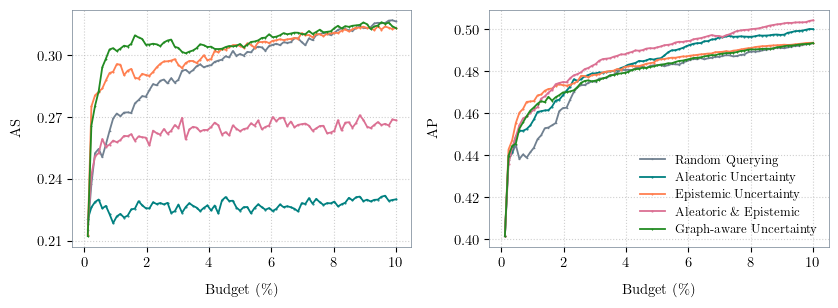

In [6]:
from matplotlib.ticker import MaxNLocator

al_single_df["budget_pct"] = al_single_df["n_labeled"] / AL_SINGLE_N_DATA * 100

fig, (ax_as, ax_ap) = plt.subplots(1, 2, figsize=(8.5, 3.2))   # wider than the default single-panel figsize -- was too tall/square per panel

for strategy in AL_SINGLE_STRATEGIES:
    sub = al_single_df[al_single_df["strategy"] == strategy]
    ax_as.plot(sub["budget_pct"], sub["AS_strict"], marker=STRATEGY_MARKERS_SINGLE[strategy],
               color=STRATEGY_COLORS_SINGLE[strategy], linewidth=1.3, markersize=0.5)
    ax_ap.plot(sub["budget_pct"], sub["AP"], marker=STRATEGY_MARKERS_SINGLE[strategy],
               color=STRATEGY_COLORS_SINGLE[strategy], linewidth=1.3, markersize=0.5,
               label=STRATEGY_LABELS[strategy])

ax_as.set_xlabel(r"Budget (\%)")
ax_ap.set_xlabel(r"Budget (\%)")
ax_as.set_ylabel("AS")
ax_ap.set_ylabel("AP")
ax_as.yaxis.set_major_locator(MaxNLocator(nbins=4))
ax_as.grid(True, ls=":", alpha=0.6)
ax_ap.grid(True, ls=":", alpha=0.6)

ax_ap.legend(fontsize=9, frameon=False)

plt.tight_layout()
plt.savefig("plots/active_learning_single_query_trajectory.pdf", dpi=300, bbox_inches="tight")
plt.show()

**Interpretation: why AP stays flat while AS_strict varies widely.**
At the 10% budget, AP stays essentially flat across all five query strategies
(49.3-50.4%), while AS\_strict ranges from 23.0% to 31.6% -- a real difference
in what the two metrics are sensitive to, not noise. AP is a *ranking-only*
metric: it only asks whether PLS's propagated objectness score orders true
objects above non-objects correctly, and that ordering survives largely intact
regardless of which nodes get queried, since the overall separability between
object and non-object evidence in the graph changes little with acquisition
strategy. AS\_strict, by contrast, depends on the *calibration* of PLS's full
propagated class-probability distribution, not just its ranking -- it
penalizes soft labels that are confidently wrong, not only mis-ordered ones.
Entropy-driven querying (Aleatoric) concentrates the labeling budget on exactly
the highest-entropy, most disputed nodes in the graph -- precisely where
neighboring detections' soft-label estimates already disagree most. Revealing
hard labels there forces propagation to reconcile more local disagreement
throughout the graph, and because `solve_conventional` draws its supervision
via Monte-Carlo one-hot sampling of the revealed labels, concentrating that
sampling on the most contested regions injects more noise into the propagated
soft-label distribution -- degrading AS\_strict even as AP, which never sees
this noise because it only cares about relative order, stays flat. Epistemic
querying (evidence starvation) and Random largely avoid this failure mode since
neither preferentially targets disputed regions (AS\_strict 31.3/31.6,
essentially tied), while Mixture -- blending in some entropy signal -- lands in
between (26.8), worse than pure Epistemic/Random but better than pure Aleatoric
(23.0). Graph-aware Uncertainty (the heat-kernel-weighted mean Wilson interval
width, `wilson_kernel_norm` in `active_querying.py`) ends tied with
Epistemic/Random at 10% (31.3), but has the best AS\_strict of all strategies at
71 of the 86 checkpoints, with its lead concentrated in the low-budget range
(e.g. 30.5 vs. 29.0 for Epistemic at 1,100 labels, ~1.3%); beyond ~5% it
plateaus while the others catch up. All numbers come from a single run per
strategy; at the shared 100-label starting point, AS\_strict already differs by
up to ~1 point between strategies purely from Monte-Carlo sampling.